# Modélisation — Partie 1 : modèle traditionnel (WoE + régression logistique)
**Objectif :** construire le modèle qu'utilisent les banques : découper les variables en classes, calculer le WoE et l'IV, faire une régression logistique, puis la transformer en **grille de score par points**.  
**Données :** `data/train.csv`, `data/val.csv` (sorties de `02_preparation`). Le test n'est pas utilisé ici, il est gardé pour la comparaison finale avec LightGBM.

Étapes :
1. découper chaque variable en **classes** (tranches)
2. calculer le **WoE** de chaque classe et l'**IV** de chaque variable (sur le train uniquement)
3. **régression logistique** sur les WoE
4. transformer les coefficients en **grille de score**
5. évaluer sur la validation (AUC, Gini, KS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path().resolve().parent
DATA = ROOT / 'data'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)

TARGET = 'SeriousDlqin2yrs'

train = pd.read_csv(DATA / 'train.csv', index_col=0)
val = pd.read_csv(DATA / 'val.csv', index_col=0)
test = pd.read_csv(DATA / 'test.csv', index_col=0)

print('Train :', train.shape, '| Validation :', val.shape)

Train : (89634, 14) | Validation : (29878, 14)


---
## 1. Découpage des variables en classes
Pourquoi découper au lieu de garder les valeurs brutes ?
- on a vu dans l'exploration que plusieurs relations ne sont **pas linéaires** (U, seuils) ==> une régression logistique sur les valeurs brutes les rate
- les valeurs extrêmes ne posent plus de problème (elles tombent dans la dernière classe)
- c'est lisible : « client de moins de 30 ans » au lieu de « âge × 0,03 »

Règles pour choisir les bornes :
- au moins ~1 % des clients par classe (sinon le WoE n'est pas fiable)
- un risque qui évolue de façon **logique** d'une classe à l'autre
- des bornes « rondes », faciles à expliquer

Les bornes viennent des graphiques de taux de défaut de l'exploration, vérifiées sur le train. Les classes trop proches ont été regroupées (ex : DebtRatio 0-0,2 et 0,2-0,4 ont le même risque ==> une seule classe 0-0,4).

In [2]:
inf = np.inf

# bornes des classes : [a, b[ -> a inclus, b exclu
BORNES = {
    'RevolvingUtilizationOfUnsecuredLines': [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1, inf],
    'age':                                  [0, 30, 40, 50, 60, 70, inf],
    'NumberOfTime30-59DaysPastDueNotWorse': [0, 1, 2, 3, inf],
    'NumberOfTime60-89DaysPastDueNotWorse': [0, 1, 2, inf],
    'NumberOfTimes90DaysLate':              [0, 1, 2, inf],
    'DebtRatio':                            [0, 0.4, 0.6, 0.8, inf],
    'MonthlyIncome':                        [0, 3500, 5000, 7500, 10000, inf],
    'NumberOfOpenCreditLinesAndLoans':      [0, 1, 3, 6, inf],
    'NumberRealEstateLoansOrLines':         [0, 1, 3, 4, inf],
    'NumberOfDependents':                   [0, 1, 2, 3, inf],
}

# variables entieres (comptages) -> etiquettes du type '0', '1-2', '3+'
ENTIERES = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate', 'NumberOfOpenCreditLinesAndLoans',
            'NumberRealEstateLoansOrLines', 'NumberOfDependents']


def etiquettes(col):
    # construit un nom lisible pour chaque classe
    b = BORNES[col]
    noms = []
    for a, c in zip(b[:-1], b[1:]):
        if c == inf:
            noms.append(f'{a}+' if col in ENTIERES else f'>= {a}')
        elif col in ENTIERES:
            noms.append(str(a) if c - a == 1 else f'{a}-{c - 1}')
        else:
            noms.append(f'{a} - {c}')
    return noms


for col in BORNES:
    print(col, ':', etiquettes(col))

RevolvingUtilizationOfUnsecuredLines : ['0 - 0.1', '0.1 - 0.3', '0.3 - 0.5', '0.5 - 0.7', '0.7 - 0.9', '0.9 - 1', '>= 1']
age : ['0 - 30', '30 - 40', '40 - 50', '50 - 60', '60 - 70', '>= 70']
NumberOfTime30-59DaysPastDueNotWorse : ['0', '1', '2', '3+']
NumberOfTime60-89DaysPastDueNotWorse : ['0', '1', '2+']
NumberOfTimes90DaysLate : ['0', '1', '2+']
DebtRatio : ['0 - 0.4', '0.4 - 0.6', '0.6 - 0.8', '>= 0.8']
MonthlyIncome : ['0 - 3500', '3500 - 5000', '5000 - 7500', '7500 - 10000', '>= 10000']
NumberOfOpenCreditLinesAndLoans : ['0', '1-2', '3-5', '6+']
NumberRealEstateLoansOrLines : ['0', '1-2', '3', '4+']
NumberOfDependents : ['0', '1', '2', '3+']


**Classes spéciales.** Certaines infos de la préparation deviennent leur propre classe, au lieu d'être une colonne à part :
- `MonthlyIncome` : classes **« manquant »** et **« 0 ou 1 »** (indicateurs `revenu_manquant`, `revenu_0_1`)
- `DebtRatio` : classe **« sans revenu »** (sans revenu fiable, le DebtRatio n'était pas un vrai rapport)
- `NumberOfTimes90DaysLate` : classe **« code 96/98 »** (indicateur `retards_code_special`)

C'est comme ça qu'on fait dans les grilles bancaires : un client sans revenu renseigné reçoit des points pour « revenu non renseigné ».

In [3]:
def classer(d):
    # renvoie un DataFrame avec la classe de chaque client pour chaque variable
    classes = pd.DataFrame(index=d.index)
    sans_revenu = (d['revenu_manquant'] == 1) | (d['revenu_0_1'] == 1)

    for col in BORNES:
        # cut() range chaque valeur dans sa classe, right=False -> [a, b[
        c = pd.cut(d[col], BORNES[col], right=False, labels=etiquettes(col)).astype(str)

        if col == 'MonthlyIncome':
            c = c.where(d['revenu_manquant'] == 0, 'manquant')
            c = c.where(d['revenu_0_1'] == 0, '0 ou 1')
        if col == 'DebtRatio':
            c = c.where(~sans_revenu, 'sans revenu')
        if col == 'NumberOfTimes90DaysLate':
            c = c.where(d['retards_code_special'] == 0, 'code 96/98')

        classes[col] = c
    return classes


classes_train = classer(train)
classes_val = classer(val)
classes_test = classer(test)

classes_train.head()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,NumberOfDependents
9918,0.3 - 0.5,30 - 40,0,0,0,0.4 - 0.6,0 - 3500,6+,1-2,0
82643,0.3 - 0.5,60 - 70,0,0,0,sans revenu,manquant,6+,1-2,0
58880,0 - 0.1,30 - 40,0,0,0,0 - 0.4,>= 10000,6+,1-2,2
91080,0.7 - 0.9,60 - 70,0,0,0,0.6 - 0.8,0 - 3500,6+,1-2,0
93799,0 - 0.1,30 - 40,0,0,0,0 - 0.4,0 - 3500,3-5,0,3+


---
## 2. Weight of Evidence (WoE) et Information Value (IV)

### WoE : le risque de chaque classe
**WoE = ln( % des bons de la classe ÷ % des mauvais de la classe )**

- **% des bons de la classe** : parmi tous les bons clients du train (cible = 0), la part qui est dans cette classe
- **% des mauvais de la classe** : parmi tous les clients en défaut du train (cible = 1), la part qui est dans cette classe
- **ln** : logarithme. Il rend le WoE symétrique : 2 fois plus de bons que de mauvais ==> +0,69, 2 fois moins ==> −0,69

Comment le lire :
- **WoE > 0** : la classe a proportionnellement plus de bons clients ==> **moins risquée** que la moyenne
- **WoE < 0** : plus de mauvais clients ==> **plus risquée**
- **WoE = 0** : risque moyen

### IV : la force de chaque variable
**IV = Σ ( % des bons − % des mauvais ) × WoE**, sur toutes les classes de la variable

- l'IV mesure si la variable **sépare bien** les bons des mauvais clients
- chaque terme est toujours ≥ 0, donc plus il y a de classes très différentes de la moyenne, plus l'IV est grand

| IV | Pouvoir prédictif |
|---|---|
| < 0,02 | inutile |
| 0,02 - 0,1 | faible |
| 0,1 - 0,3 | moyen |
| 0,3 - 0,5 | fort |
| > 0,5 | très fort (à vérifier : trop beau ?) |

**Calculé sur le train uniquement**, puis les WoE sont appliqués tels quels à la validation et au test.

In [4]:
nb_bons = (train[TARGET] == 0).sum()
nb_mauvais = (train[TARGET] == 1).sum()
print('Bons clients (train) :', nb_bons, '| Mauvais clients (train) :', nb_mauvais)

tables_woe = {}
iv = {}

for col in BORNES:
    t = train.groupby(classes_train[col])[TARGET].agg(nb_clients='size', nb_mauvais='sum')
    t['nb_bons'] = t['nb_clients'] - t['nb_mauvais']
    t['taux_defaut'] = t['nb_mauvais'] / t['nb_clients']
    t['pct_bons'] = t['nb_bons'] / nb_bons
    t['pct_mauvais'] = t['nb_mauvais'] / nb_mauvais
    t['woe'] = np.log(t['pct_bons'] / t['pct_mauvais'])
    t['iv'] = (t['pct_bons'] - t['pct_mauvais']) * t['woe']

    # remettre les classes dans l'ordre logique (cut + classes speciales a la fin)
    ordre = [e for e in etiquettes(col) if e in t.index] + [e for e in t.index if e not in etiquettes(col)]
    tables_woe[col] = t.reindex(ordre)
    iv[col] = t['iv'].sum()

tables_woe['RevolvingUtilizationOfUnsecuredLines'].round(3)

Bons clients (train) : 83629 | Mauvais clients (train) : 6005


,nb_clients,nb_mauvais,nb_bons,taux_defaut,pct_bons,pct_mauvais,woe,iv
RevolvingUtilizationOfUnsecuredLines,,,,,,,,
0 - 0.1,38529,696,37833,0.018,0.452,0.116,1.362,0.458
0.1 - 0.3,17136,548,16588,0.032,0.198,0.091,0.776,0.083
0.3 - 0.5,9475,540,8935,0.057,0.107,0.090,0.172,0.003
0.5 - 0.7,6849,664,6185,0.097,0.074,0.111,-0.402,0.015
0.7 - 0.9,5968,906,5062,0.152,0.061,0.151,-0.913,0.083
0.9 - 1,9830,1919,7911,0.195,0.095,0.320,-1.217,0.274
>= 1,1847,732,1115,0.396,0.013,0.122,-2.213,0.240


**Exemple de calcul** (1re ligne, utilisation du crédit entre 0 et 0,1) :
- 38 529 clients dont 696 mauvais ==> 37 833 bons
- % des bons = 37 833 ÷ 83 629 = 45,2 % — % des mauvais = 696 ÷ 6 005 = 11,6 %
- WoE = ln(45,2 ÷ 11,6) = ln(3,9) = **+1,36** ==> classe beaucoup moins risquée que la moyenne (1,8 % de défaut)

Le WoE descend régulièrement d'une classe à l'autre jusqu'à −2,2 pour les clients au-dessus de leur plafond ==> relation logique.

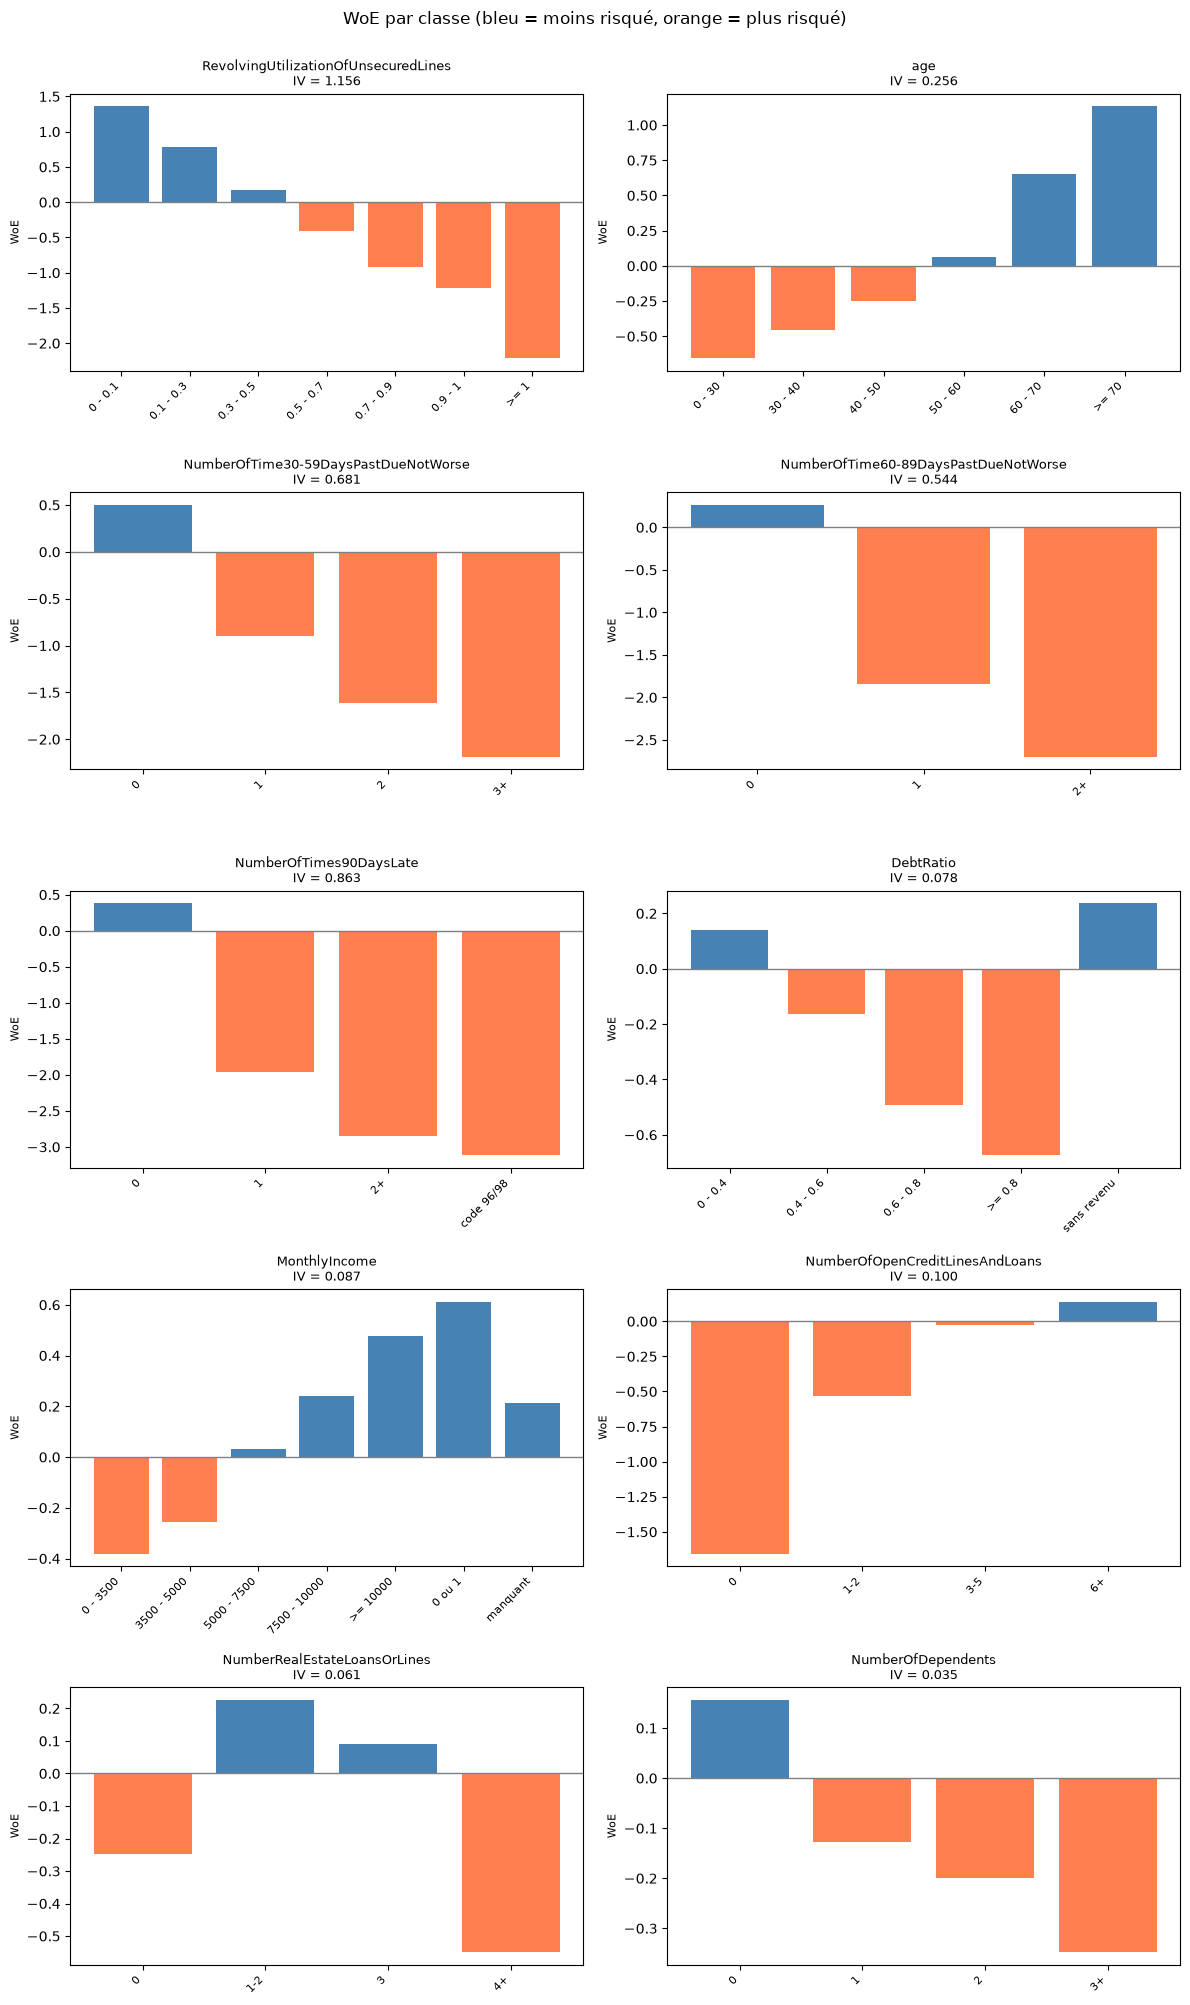

In [5]:
# WoE de toutes les variables
fig, axes = plt.subplots(5, 2, figsize=(12, 20))

for ax, col in zip(axes.ravel(), BORNES):
    t = tables_woe[col]
    couleurs = ['steelblue' if w >= 0 else 'coral' for w in t['woe']]
    ax.bar(range(len(t)), t['woe'], color=couleurs)
    ax.axhline(0, color='grey', lw=1)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=45, ha='right', fontsize=8)
    ax.set_title(f'{col}\nIV = {iv[col]:.3f}', fontsize=9)
    ax.set_ylabel('WoE', fontsize=8)

fig.suptitle('WoE par classe (bleu = moins risqué, orange = plus risqué)', y=1.0)
plt.tight_layout()
plt.show()

- Utilisation du crédit, âge, les 3 variables de retards : WoE **monotone** (toujours dans le même sens) ==> logique.
- Retards 90 j : la classe « code 96/98 » a le WoE le plus bas (−3,1) ==> ces clients sont les plus risqués, cohérent avec l'exploration.
- DebtRatio : plus on est endetté plus c'est risqué, et « sans revenu » est légèrement moins risqué que la moyenne (cohérent : ces clients font moins défaut).
- Prêts immobiliers : forme en U (0 prêt ou 4+ = plus risqué). C'est logique métier : 1-3 prêts = propriétaire stable, 0 = pas de bien, 4+ = beaucoup de dettes immobilières.

In [6]:
iv_table = pd.DataFrame({'IV': pd.Series(iv)}).sort_values('IV', ascending=False)

def force(x):
    if x < 0.02: return 'inutile'
    if x < 0.1:  return 'faible'
    if x < 0.3:  return 'moyen'
    if x < 0.5:  return 'fort'
    return 'très fort'

iv_table['pouvoir prédictif'] = iv_table['IV'].apply(force)
iv_table.round(3)

,IV,pouvoir prédictif
RevolvingUtilizationOfUnsecuredLines,1.156,très fort
NumberOfTimes90DaysLate,0.863,très fort
NumberOfTime30-59DaysPastDueNotWorse,0.681,très fort
NumberOfTime60-89DaysPastDueNotWorse,0.544,très fort
age,0.256,moyen
NumberOfOpenCreditLinesAndLoans,0.100,moyen
MonthlyIncome,0.087,faible
DebtRatio,0.078,faible
NumberRealEstateLoansOrLines,0.061,faible
NumberOfDependents,0.035,faible


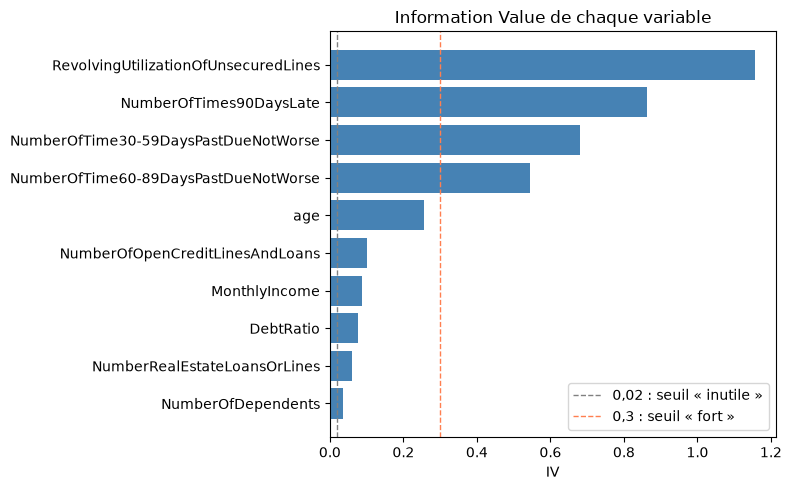

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(iv_table.index, iv_table['IV'], color='steelblue')
ax.axvline(0.02, color='grey', linestyle='--', lw=1, label='0,02 : seuil « inutile »')
ax.axvline(0.3, color='coral', linestyle='--', lw=1, label='0,3 : seuil « fort »')
ax.invert_yaxis()
ax.set_title('Information Value de chaque variable')
ax.set_xlabel('IV')
ax.legend()
plt.tight_layout()
plt.show()

- Aucune variable sous 0,02 ==> on n'en retire aucune à ce stade.
- **Très fortes** : utilisation du crédit, les 3 variables de retards ==> exactement ce qu'on avait vu dans l'exploration.
- Utilisation du crédit a un IV > 1. Normalement un IV > 0,5 doit faire vérifier qu'il n'y a pas de fuite (une variable qui contiendrait la réponse). Ici non : elle est mesurée **avant** la période de 2 ans observée, et c'est connu dans le métier comme l'un des meilleurs prédicteurs du défaut.
- Âge = moyen, crédits en cours = juste à la limite moyen / faible (0,10) ; revenu, DebtRatio, prêts immobiliers, personnes à charge = faibles.

---
## 3. Régression logistique sur les WoE
On remplace chaque valeur par le **WoE de sa classe**, puis on fait une régression logistique :

**PD = 1 ÷ ( 1 + e^−(α + β₁ × WoE₁ + β₂ × WoE₂ + …) )**

- **PD** : probabilité de défaut prédite pour le client
- **α** (intercept) : point de départ, lié au taux de défaut moyen
- **βᵢ** : coefficient de la variable i = combien elle pèse
- **WoEᵢ** : WoE de la classe du client pour la variable i

Comme WoE > 0 = moins risqué et qu'on prédit le défaut, **tous les coefficients doivent être négatifs**. Un coefficient positif voudrait dire « moins risqué ==> plus de défaut », ce qui n'a pas de sens : souvent c'est que la variable fait doublon avec une autre.

In [8]:
def en_woe(classes, variables):
    # remplace chaque classe par son WoE (classe jamais vue dans le train -> WoE = 0 = risque moyen)
    return pd.DataFrame({col: classes[col].map(tables_woe[col]['woe']).fillna(0) for col in variables})

variables = list(BORNES)
X_train = en_woe(classes_train, variables)
y_train = train[TARGET]

# C tres grand = pas de penalisation, regression logistique classique
modele = LogisticRegression(C=1e6, max_iter=1000)
modele.fit(X_train, y_train)

pd.DataFrame({'coefficient': modele.coef_[0]}, index=variables).round(3)

,coefficient
RevolvingUtilizationOfUnsecuredLines,-0.596
age,-0.424
NumberOfTime30-59DaysPastDueNotWorse,-0.535
NumberOfTime60-89DaysPastDueNotWorse,-0.407
NumberOfTimes90DaysLate,-0.545
DebtRatio,-0.923
MonthlyIncome,0.027
NumberOfOpenCreditLinesAndLoans,-0.198
NumberRealEstateLoansOrLines,-0.625
NumberOfDependents,-0.151


In [9]:
# correlation entre les variables WoE : est-ce que MonthlyIncome fait doublon ?
X_train.corr()['MonthlyIncome'].round(2).sort_values()

NumberOfDependents                     -0.09
NumberOfTime30-59DaysPastDueNotWorse    0.04
NumberOfTime60-89DaysPastDueNotWorse    0.06
age                                     0.09
NumberOfTimes90DaysLate                 0.09
RevolvingUtilizationOfUnsecuredLines    0.13
NumberOfOpenCreditLinesAndLoans         0.13
NumberRealEstateLoansOrLines            0.15
DebtRatio                               0.32
MonthlyIncome                           1.00
Name: MonthlyIncome, dtype: float64

`MonthlyIncome` a un coefficient **positif et presque nul** (+0,03) ==> une fois les autres variables connues, le revenu n'apporte plus rien. Ses infos utiles (revenu manquant, revenu 0-1) sont déjà dans la classe « sans revenu » de `DebtRatio`, et le niveau de revenu est lié à l'âge, à l'utilisation du crédit et aux prêts immobiliers.

**Choix :** on retire `MonthlyIncome` et on refait la régression.

In [10]:
variables = [v for v in BORNES if v != 'MonthlyIncome']

X_train = en_woe(classes_train, variables)
X_val = en_woe(classes_val, variables)
X_test = en_woe(classes_test, variables)

modele = LogisticRegression(C=1e6, max_iter=1000)
modele.fit(X_train, y_train)

coefs = pd.DataFrame({'coefficient': modele.coef_[0], 'IV': [iv[v] for v in variables]}, index=variables)
print('Intercept α :', round(modele.intercept_[0], 3))
coefs.round(3)

Intercept α : -2.615


,coefficient,IV
RevolvingUtilizationOfUnsecuredLines,-0.595,1.156
age,-0.427,0.256
NumberOfTime30-59DaysPastDueNotWorse,-0.535,0.681
NumberOfTime60-89DaysPastDueNotWorse,-0.406,0.544
NumberOfTimes90DaysLate,-0.546,0.863
DebtRatio,-0.916,0.078
NumberOfOpenCreditLinesAndLoans,-0.197,0.100
NumberRealEstateLoansOrLines,-0.605,0.061
NumberOfDependents,-0.129,0.035


Tous les coefficients sont négatifs ==> le modèle est cohérent : chaque variable va dans le sens attendu.

---
## 4. Grille de score par points
Une banque n'utilise pas directement la PD : elle donne au conseiller une **grille**. Chaque classe de chaque variable vaut un nombre de points, on additionne ==> **score**. Plus le score est haut, moins le client est risqué.

**Score = Offset + Facteur × ln(odds)**

- **odds** : nombre de bons clients pour 1 mauvais = (1 − PD) ÷ PD
- **Facteur = PDO ÷ ln(2)**
- **Offset = Score de référence − Facteur × ln(odds de référence)**

On choisit 3 paramètres (choix classiques en banque) :
- **score de référence = 600** points…
- … qui correspond à des **odds de 50 pour 1** (50 bons pour 1 mauvais, PD ≈ 2 %)
- **PDO = 20** (*Points to Double the Odds*) : **+20 points = risque divisé par 2**

Points d'une classe j de la variable i :

**Points = − Facteur × βᵢ × WoEᵢⱼ + (Offset − Facteur × α) ÷ n**

- **−Facteur × βᵢ × WoEᵢⱼ** : la part propre à la classe (β < 0 et WoE > 0 ==> points positifs)
- **(Offset − Facteur × α) ÷ n** : la base, partagée en parts égales entre les **n** variables

In [11]:
SCORE_REF = 600
ODDS_REF = 50
PDO = 20

facteur = PDO / np.log(2)
offset = SCORE_REF - facteur * np.log(ODDS_REF)
n = len(variables)
alpha = modele.intercept_[0]

print('Facteur :', round(facteur, 2))
print('Offset  :', round(offset, 2))

lignes = []
for beta, col in zip(modele.coef_[0], variables):
    t = tables_woe[col]
    for classe, woe in t['woe'].items():
        points = -facteur * beta * woe + (offset - facteur * alpha) / n
        lignes.append({'variable': col, 'classe': classe, 'nb_clients (train)': t.loc[classe, 'nb_clients'],
                       'taux_defaut (train)': t.loc[classe, 'taux_defaut'], 'woe': woe, 'points': round(points)})

grille = pd.DataFrame(lignes)
grille.round(3)

Facteur : 28.85
Offset  : 487.12


,variable,classe,nb_clients (train),taux_defaut (train),woe,points
0,RevolvingUtilizationOfUnsecuredLines,0 - 0.1,38529,0.018,1.362,86
1,RevolvingUtilizationOfUnsecuredLines,0.1 - 0.3,17136,0.032,0.776,76
2,RevolvingUtilizationOfUnsecuredLines,0.3 - 0.5,9475,0.057,0.172,65
3,RevolvingUtilizationOfUnsecuredLines,0.5 - 0.7,6849,0.097,-0.402,56
4,RevolvingUtilizationOfUnsecuredLines,0.7 - 0.9,5968,0.152,-0.913,47
5,RevolvingUtilizationOfUnsecuredLines,0.9 - 1,9830,0.195,-1.217,42
6,RevolvingUtilizationOfUnsecuredLines,>= 1,1847,0.396,-2.213,25
7,age,0 - 30,5083,0.122,-0.656,54
8,age,30 - 40,13949,0.102,-0.458,57
9,age,40 - 50,20585,0.085,-0.252,59


Lecture : un client qui utilise moins de 10 % de son crédit gagne **86 points**, un client qui dépasse son plafond seulement **25**. Une classe « code 96/98 » sur les retards de 90 jours ne donne que **13 points**.

Les variables qui pèsent le plus sont celles où l'**écart** entre la meilleure et la pire classe est le plus grand :

In [12]:
ecart = grille.groupby('variable')['points'].agg(['min', 'max'])
ecart['écart'] = ecart['max'] - ecart['min']
ecart.sort_values('écart', ascending=False)

,min,max,écart
variable,,,
RevolvingUtilizationOfUnsecuredLines,25,86,61
NumberOfTimes90DaysLate,13,69,56
NumberOfTime30-59DaysPastDueNotWorse,29,70,41
NumberOfTime60-89DaysPastDueNotWorse,31,66,35
DebtRatio,45,69,24
age,54,76,22
NumberRealEstateLoansOrLines,53,66,13
NumberOfOpenCreditLinesAndLoans,53,63,10
NumberOfDependents,61,63,2


- les **retards de 90 jours** (56 points d'écart) et l'**utilisation du crédit** (61 points) pèsent le plus
- `NumberOfDependents` ne fait varier le score que de 2 points ==> quasiment aucun poids, on pourrait le retirer pour une grille plus simple

In [13]:
def score(classes):
    # additionne les points de chaque variable
    total = pd.Series(0, index=classes.index)
    for col in variables:
        pts = grille[grille['variable'] == col].set_index('classe')['points']
        total = total + classes[col].map(pts)
    return total

score_train = score(classes_train)
score_val = score(classes_val)
score_test = score(classes_test)

print('Score min / médian / max (validation) :', score_val.min(), '/', score_val.median(), '/', score_val.max())

Score min / médian / max (validation) : 384 / 592.0 / 628


### Exemple : le score d'un client

In [14]:
client = classes_val.iloc[0]

detail = []
for col in variables:
    pts = grille[(grille['variable'] == col) & (grille['classe'] == client[col])]['points'].iloc[0]
    detail.append((col, client[col], pts))

detail = pd.DataFrame(detail, columns=['variable', 'classe du client', 'points'])
print(detail.to_string(index=False))
print()
print('SCORE TOTAL :', detail['points'].sum())
print('Défaut réel :', val.iloc[0][TARGET])

                            variable classe du client  points
RevolvingUtilizationOfUnsecuredLines        0.5 - 0.7      56
                                 age            >= 70      76
NumberOfTime30-59DaysPastDueNotWorse                0      70
NumberOfTime60-89DaysPastDueNotWorse                0      66
             NumberOfTimes90DaysLate                0      69
                           DebtRatio        0.4 - 0.6      58
     NumberOfOpenCreditLinesAndLoans               6+      63
        NumberRealEstateLoansOrLines              1-2      66
                  NumberOfDependents                0      63

SCORE TOTAL : 587
Défaut réel : 0.0


---
## 5. Évaluation sur la validation

### Les 3 indicateurs
- **AUC** : si on prend au hasard un client en défaut et un client qui rembourse, probabilité que le modèle donne le risque le plus élevé au client en défaut. 0,5 = hasard, 1 = parfait.
- **Gini = 2 × AUC − 1** : même info, échelle utilisée en banque. 0 = hasard, 1 = parfait.
- **KS** : plus grand écart entre la courbe cumulée des bons et celle des mauvais quand on trie les clients par score. Plus c'est grand, mieux le modèle sépare les 2 groupes.

In [15]:
def evaluer(y, pd_predite):
    auc = roc_auc_score(y, pd_predite)
    fpr, tpr, _ = roc_curve(y, pd_predite)
    ks = (tpr - fpr).max()
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks}

# predict_proba()[:, 1] -> probabilite de la classe 1 = PD
pd_train = modele.predict_proba(X_train)[:, 1]
pd_val = modele.predict_proba(X_val)[:, 1]

resultats = pd.DataFrame({
    'train': evaluer(y_train, pd_train),
    'validation (PD)': evaluer(val[TARGET], pd_val),
    'validation (grille arrondie)': evaluer(val[TARGET], -score_val),   # score haut = peu risque -> on inverse
}).T
resultats.round(3)

,AUC,Gini,KS
train,0.859,0.717,0.559
validation (PD),0.859,0.719,0.557
validation (grille arrondie),0.859,0.719,0.557


- **AUC ≈ 0,86, Gini ≈ 0,72, KS ≈ 0,56** sur la validation ==> très bon pour un modèle de scoring (en banque un Gini > 0,6 est considéré comme bon).
- Train et validation quasi identiques ==> **pas de surapprentissage**, le modèle généralise bien.
- La grille avec les points arrondis donne le même résultat que la PD exacte ==> l'arrondi ne coûte rien.

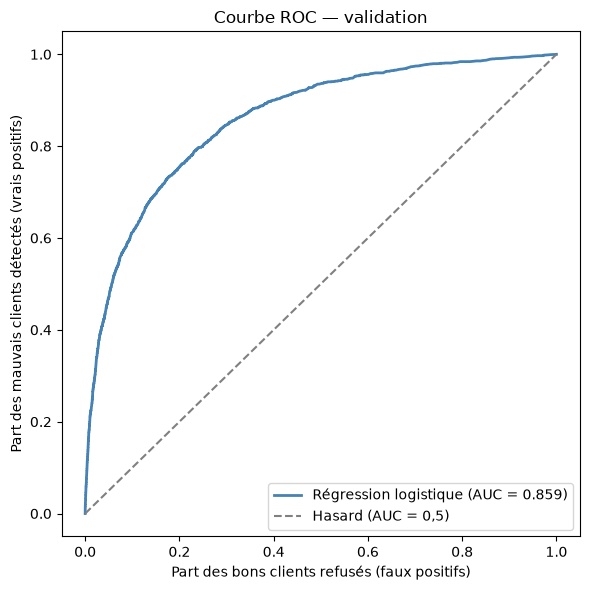

In [16]:
fpr, tpr, _ = roc_curve(val[TARGET], pd_val)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='steelblue', lw=2, label=f'Régression logistique (AUC = {roc_auc_score(val[TARGET], pd_val):.3f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Hasard (AUC = 0,5)')
ax.set_xlabel('Part des bons clients refusés (faux positifs)')
ax.set_ylabel('Part des mauvais clients détectés (vrais positifs)')
ax.set_title('Courbe ROC — validation')
ax.legend()
plt.tight_layout()
plt.show()

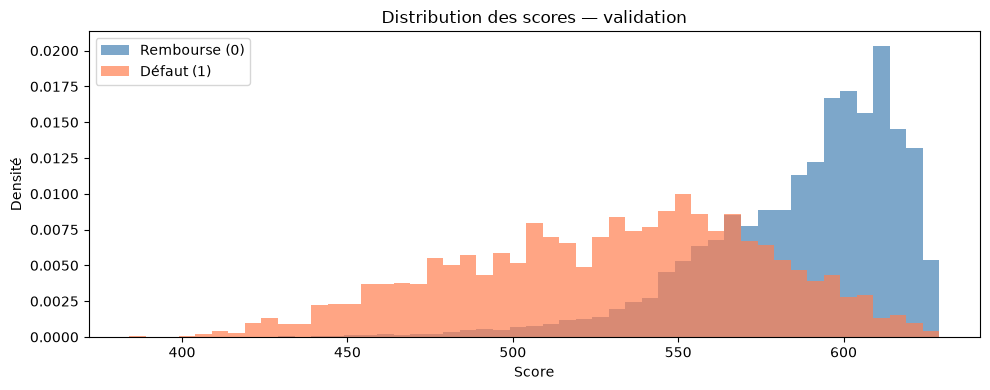

In [17]:
# distribution des scores : bons vs mauvais clients
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(score_val.min(), score_val.max() + 5, 5)
ax.hist(score_val[val[TARGET] == 0], bins=bins, color='steelblue', alpha=0.7, density=True, label='Rembourse (0)')
ax.hist(score_val[val[TARGET] == 1], bins=bins, color='coral', alpha=0.7, density=True, label='Défaut (1)')
ax.set_xlabel('Score')
ax.set_ylabel('Densité')
ax.set_title('Distribution des scores — validation')
ax.legend()
plt.tight_layout()
plt.show()

Les mauvais clients (orange) sont nettement décalés vers les scores bas ==> la grille sépare bien les 2 groupes. Il reste une zone de recouvrement entre ~550 et ~600, c'est là que le modèle se trompe le plus.

In [18]:
# taux de defaut par tranche de score (10 tranches de meme taille)
tranches_score = pd.qcut(score_val, 10, duplicates='drop')
par_tranche = val.groupby(tranches_score, observed=True)[TARGET].agg(nb_clients='size', taux_defaut='mean')
par_tranche['taux_defaut'] = (par_tranche['taux_defaut'] * 100).round(1)
par_tranche

,nb_clients,taux_defaut
"(383.999, 538.0]",3004,35.9
"(538.0, 558.0]",2978,11.8
"(558.0, 572.0]",3135,6.7
"(572.0, 583.0]",2894,4.7
"(583.0, 592.0]",3051,2.6
"(592.0, 599.0]",3247,1.7
"(599.0, 605.0]",2678,1.2
"(605.0, 611.0]",3200,0.9
"(611.0, 617.0]",2955,0.6
"(617.0, 628.0]",2736,0.5


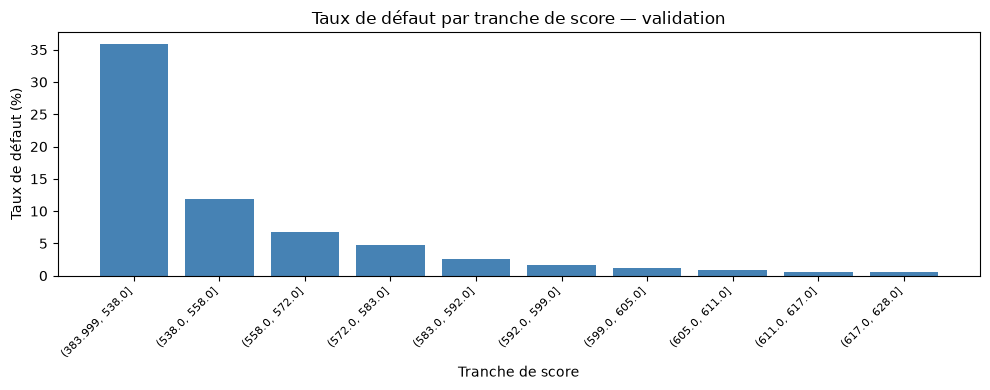

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(par_tranche)), par_tranche['taux_defaut'], color='steelblue')
ax.set_xticks(range(len(par_tranche)))
ax.set_xticklabels([str(t) for t in par_tranche.index], rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Tranche de score')
ax.set_ylabel('Taux de défaut (%)')
ax.set_title('Taux de défaut par tranche de score — validation')
plt.tight_layout()
plt.show()

Le taux de défaut baisse à chaque tranche quand le score monte ==> la grille **classe bien** les clients du plus risqué au moins risqué. Les 10 % de scores les plus bas (≤ 538) ont 36 % de défaut et regroupent à eux seuls **plus de la moitié des défauts** (~1 080 sur 2 002).

---
## 6. Sauvegarde
- la grille de score ==> `reports/grille_score.csv` (c'est un livrable, elle peut aller sur GitHub)
- les PD et scores sur validation et test ==> `data/` pour la comparaison avec LightGBM (le test n'est **pas évalué** ici)

In [20]:
grille.to_csv(REPORTS / 'grille_score.csv', index=False)

pd.DataFrame({'pd_logit': pd_val, 'score': score_val}, index=val.index).to_csv(DATA / 'pred_val_logit.csv')
pd.DataFrame({'pd_logit': modele.predict_proba(X_test)[:, 1], 'score': score_test}, index=test.index).to_csv(DATA / 'pred_test_logit.csv')

print('Grille enregistrée dans', REPORTS / 'grille_score.csv')

Grille enregistrée dans /home/yassmin/Desktop/GSC/credit-scoring/reports/grille_score.csv


---
## 7. Bilan

| Étape | Choix | Pourquoi |
|---|---|---|
| Classes | Bornes rondes, ≥ ~1 % des clients, risque logique | Lisible, WoE fiable, capte les relations non linéaires |
| Classes spéciales | « manquant », « 0 ou 1 », « sans revenu », « code 96/98 » | Garder les infos de la préparation dans la grille |
| WoE / IV | Calculés sur le train uniquement | Pas de fuite vers la validation / le test |
| Sélection | Aucune variable < 0,02 d'IV ; `MonthlyIncome` retirée | Coefficient positif ≈ 0 : fait doublon avec les autres |
| Régression | 9 variables, tous les coefficients négatifs | Modèle cohérent avec le sens des WoE |
| Grille | 600 pts = odds 50:1, PDO = 20 | Conventions bancaires classiques |

**Résultat sur la validation : AUC ≈ 0,86 — Gini ≈ 0,72 — KS ≈ 0,56**, sans surapprentissage.

Prochaine étape : LightGBM, puis comparaison des 2 modèles sur le **test**.